In [18]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = []

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9"
}

for page in range(1, 17):
    url = f"https://www.goodreads.com/list/show/1.Best_Books_Ever?page={page}"
    response = requests.get(url, headers=headers)
    soup = BeautifulSoup(response.text, "html.parser")
    
    rows = soup.find_all("tr", {"itemtype": "http://schema.org/Book"})
    
    for row in rows:
        title = row.find("a", {"class": "bookTitle"}).text.strip()
        author = row.find("a", {"class": "authorName"}).text.strip()
        
        minirating = row.find("span", {"class": "minirating"}).text
        avg_rating = minirating.split(" avg rating")[0].strip()
        num_ratings = minirating.split("— ")[1].split(" ratings")[0].strip().replace(",", "")
        
        small_text = row.find("span", {"class": "smallText uitext"}).text
        score = small_text.split("score: ")[1].split(",")[0].strip().replace(",", "")
        
        data.append({
            "Judul": title,
            "Penulis": author,
            "Rating": avg_rating,
            "Jumlah_Review": num_ratings,
            "Skor": score
        })
        
    time.sleep(2)

In [3]:
df = pd.DataFrame(data)

df.to_csv("dataset_buku_goodreads.csv", index=False)

In [4]:
df['Rating'] = df['Rating'].astype(str).str.split().str[-1]
df['Rating'] = pd.to_numeric(df['Rating'])
df['Jumlah_Review'] = pd.to_numeric(df['Jumlah_Review'])
df['Skor'] = pd.to_numeric(df['Skor'])

print(df.dtypes)

Judul                str
Penulis              str
Rating           float64
Jumlah_Review      int64
Skor               int64
dtype: object


In [5]:
df.shape

(1600, 5)

In [6]:
df.head()

,Judul,Penulis,Rating,Jumlah_Review,Skor
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4.36,10294754,4
1,Pride and Prejudice,Jane Austen,4.30,5018564,3
2,To Kill a Mockingbird,Harper Lee,4.26,7132844,2
3,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling,4.50,3934749,2
4,The Book Thief,Markus Zusak,4.39,2983236,2


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Judul          1600 non-null   str    
 1   Penulis        1600 non-null   str    
 2   Rating         1600 non-null   float64
 3   Jumlah_Review  1600 non-null   int64  
 4   Skor           1600 non-null   int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 62.6 KB


In [8]:
df.dtypes

Judul                str
Penulis              str
Rating           float64
Jumlah_Review      int64
Skor               int64
dtype: object

In [9]:
df.isna().sum()

Judul            0
Penulis          0
Rating           0
Jumlah_Review    0
Skor             0
dtype: int64

In [10]:
kolom_numerik = ['Rating', 'Jumlah_Review', 'Skor']
pd.set_option('display.float_format', '{:.2f}'.format)
df[kolom_numerik].describe()

,Rating,Jumlah_Review,Skor
count,1600.00,1600.00,1600.00
mean,4.10,554677.19,59.96
std,0.24,971723.74,138.32
min,3.01,106.00,1.00
25%,3.95,100923.00,7.00
50%,4.10,238461.50,13.00
75%,4.27,588966.75,41.00
max,4.81,11842854.00,988.00


In [11]:
df[kolom_numerik].mode().iloc[0]

Rating              4.02
Jumlah_Review   20276.00
Skor                6.00
Name: 0, dtype: float64

In [14]:
frekuensi_penulis = df['Penulis'].value_counts().head(10)
frekuensi_judul = df['Judul'].value_counts().head(10)
print("--- TOP 10 Penulis paling banyak muncul ---")
print(frekuensi_penulis)
print("\n--- TOP 10 JUDUL BUKU (CEK DUPLIKASI) ---")
print(frekuensi_judul)

--- TOP 10 Penulis paling banyak muncul ---
Penulis
Stephen  King          22
Sarah J. Maas          20
William Shakespeare    14
J.K. Rowling           13
Rick Riordan           13
C.S. Lewis             12
Nicholas Sparks        12
Cassandra Clare        11
Richelle Mead           9
Charlaine Harris        9
Name: count, dtype: int64

--- TOP 10 JUDUL BUKU (CEK DUPLIKASI) ---
Judul
To Kill a Mockingbird                                           2
Harry Potter and the Order of the Phoenix (Harry Potter, #5)    2
1984                                                            2
Fahrenheit 451                                                  2
The Fellowship of the Ring (The Lord of the Rings, #1)          2
The Secret History                                              2
In Cold Blood                                                   2
Harry Potter and the Half-Blood Prince (Harry Potter, #6)       2
A Court of Mist and Fury (A Court of Thorns and Roses, #2)      2
Throne of Glass (Th

In [13]:
for col in kolom_numerik:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"Outlier di kolom {col}: {len(outliers)}")

Outlier di kolom Rating: 15
Outlier di kolom Jumlah_Review: 159
Outlier di kolom Skor: 218


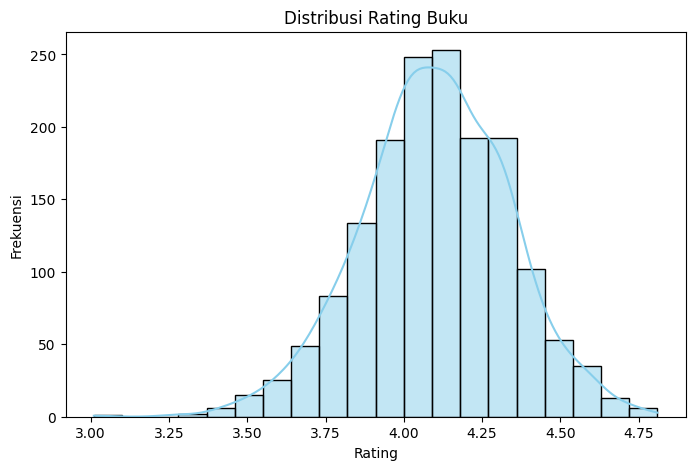

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Rating'], bins=20, kde=True, color='skyblue')
plt.title('Distribusi Rating Buku')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()

C:\Users\rayya\AppData\Local\Temp\ipykernel_7324\2356783254.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_penulis.values, y=top_penulis.index, palette='viridis')


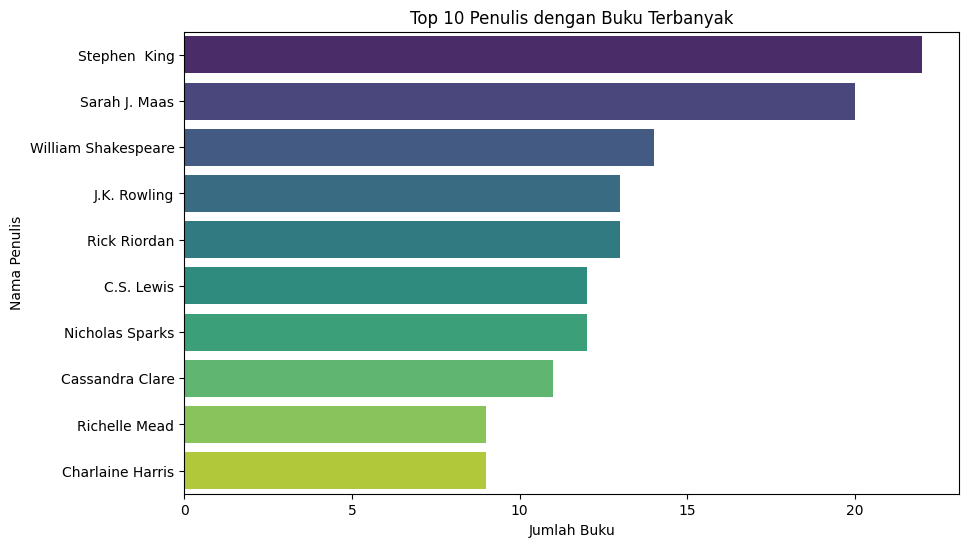

In [20]:
plt.figure(figsize=(10, 6))
top_penulis = df['Penulis'].value_counts().head(10)
sns.barplot(x=top_penulis.values, y=top_penulis.index, palette='viridis')
plt.title('Top 10 Penulis dengan Buku Terbanyak')
plt.xlabel('Jumlah Buku')
plt.ylabel('Nama Penulis')
plt.show()

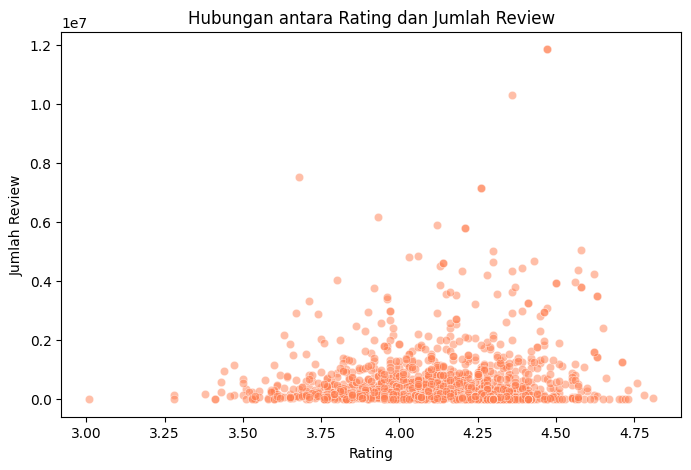

In [21]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Rating', y='Jumlah_Review', alpha=0.5, color='coral')
plt.title('Hubungan antara Rating dan Jumlah Review')
plt.xlabel('Rating')
plt.ylabel('Jumlah Review')
plt.show()

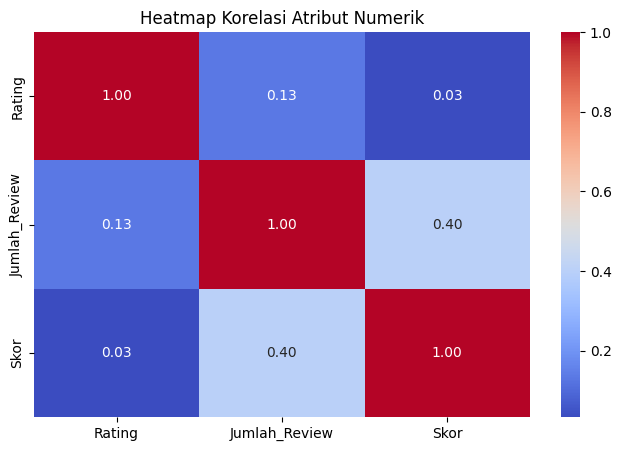

In [22]:
plt.figure(figsize=(8, 5))
kolom_numerik = ['Rating', 'Jumlah_Review', 'Skor']
matriks_korelasi = df[kolom_numerik].corr()
sns.heatmap(matriks_korelasi, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi Atribut Numerik')
plt.show()